In [1]:
import os
import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))



TensorFlow: 2.21.0
GPU: []


In [2]:
PROJECT_DIR = Path.cwd()

# Original dataset
DATASET_DIR = PROJECT_DIR / "data"

ORIGINAL_TRAIN_DIR = DATASET_DIR / "Training"
ORIGINAL_TEST_DIR = DATASET_DIR / "Testing"

# ROI dataset generated in Notebook 04
ROI_ROOT = PROJECT_DIR / "outputs" / "notebook_04" / "roi_cropped"

ROI_TRAIN_DIR = ROI_ROOT / "Training"
ROI_TEST_DIR = ROI_ROOT / "Testing"

# Notebook 05 output directories
OUTPUT_DIR = PROJECT_DIR / "outputs" / "notebook_05"

MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 10

FINE_TUNE_LAYERS = 30

print("Project directory:", PROJECT_DIR)
print("Original training:", ORIGINAL_TRAIN_DIR.exists())
print("Original testing:", ORIGINAL_TEST_DIR.exists())
print("ROI training:", ROI_TRAIN_DIR.exists())
print("ROI testing:", ROI_TEST_DIR.exists())

assert ORIGINAL_TRAIN_DIR.exists()
assert ORIGINAL_TEST_DIR.exists()
assert ROI_TRAIN_DIR.exists()
assert ROI_TEST_DIR.exists()



Project directory: e:\SEM5\ERA\ERA_Project\Brain_Tumor
Original training: True
Original testing: True
ROI training: True
ROI testing: True


In [3]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def get_image_files(folder):

    folder = Path(folder)

    return sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    ])


def get_dataset_counts(root):

    rows = []

    for split in ["Training", "Testing"]:

        for cls in CLASS_NAMES:

            folder = Path(root) / split / cls

            files = get_image_files(folder) if folder.exists() else []

            rows.append({
                "Split": split,
                "Class": cls,
                "Count": len(files)
            })

    return pd.DataFrame(rows)


original_counts = get_dataset_counts(DATASET_DIR)
roi_counts = get_dataset_counts(ROI_ROOT)

print("Original dataset:")
display(original_counts)

print("ROI dataset:")
display(roi_counts)


count_comparison = original_counts.merge(
    roi_counts,
    on=["Split", "Class"],
    suffixes=("_Original", "_ROI")
)

count_comparison["Counts_Match"] = (
    count_comparison["Count_Original"] ==
    count_comparison["Count_ROI"]
)

display(count_comparison)

assert count_comparison["Counts_Match"].all(), (
    "Image counts do not match. Check Notebook 04 ROI extraction."
)

assert (original_counts["Count"] > 0).all()
assert (roi_counts["Count"] > 0).all()



Original dataset:


,Split,Class,Count
0,Training,glioma,1400
1,Training,meningioma,1400
2,Training,notumor,1400
3,Training,pituitary,1400
4,Testing,glioma,400
5,Testing,meningioma,400
6,Testing,notumor,400
7,Testing,pituitary,400


ROI dataset:


,Split,Class,Count
0,Training,glioma,1400
1,Training,meningioma,1400
2,Training,notumor,1400
3,Training,pituitary,1400
4,Testing,glioma,400
5,Testing,meningioma,400
6,Testing,notumor,400
7,Testing,pituitary,400


,Split,Class,Count_Original,Count_ROI,Counts_Match
0,Training,glioma,1400,1400,True
1,Training,meningioma,1400,1400,True
2,Training,notumor,1400,1400,True
3,Training,pituitary,1400,1400,True
4,Testing,glioma,400,400,True
5,Testing,meningioma,400,400,True
6,Testing,notumor,400,400,True
7,Testing,pituitary,400,400,True


In [4]:
def get_relative_paths(root, split):

    paths = []

    for cls in CLASS_NAMES:

        folder = Path(root) / split / cls

        for path in get_image_files(folder):

            paths.append(
                path.relative_to(Path(root) / split).as_posix().lower()
            )

    return set(paths)


for split in ["Training", "Testing"]:

    original_paths = get_relative_paths(DATASET_DIR, split)
    roi_paths = get_relative_paths(ROI_ROOT, split)

    print(f"\n{split}")
    print("Original images:", len(original_paths))
    print("ROI images:", len(roi_paths))
    print("Missing ROI images:", len(original_paths - roi_paths))
    print("Extra ROI images:", len(roi_paths - original_paths))

    assert original_paths == roi_paths, (
        f"Original and ROI filenames do not match in {split}"
    )

print("\nDataset correspondence verified.")




Training
Original images: 5600
ROI images: 5600
Missing ROI images: 0
Extra ROI images: 0

Testing
Original images: 1600
ROI images: 1600
Missing ROI images: 0
Extra ROI images: 0

Dataset correspondence verified.


In [5]:
def create_dataframe(root):

    rows = []

    for label, cls in enumerate(CLASS_NAMES):

        folder = Path(root) / cls

        for path in get_image_files(folder):

            rows.append({
                "path": str(path),
                "label": label,
                "class_name": cls
            })

    return pd.DataFrame(rows)


def create_train_val_split(root):

    df = create_dataframe(root)

    train_df, val_df = train_test_split(
        df,
        test_size=0.20,
        random_state=SEED,
        stratify=df["label"]
    )

    return (
        train_df.reset_index(drop=True),
        val_df.reset_index(drop=True)
    )


original_train_df, original_val_df = create_train_val_split(
    ORIGINAL_TRAIN_DIR
)

roi_train_df, roi_val_df = create_train_val_split(
    ROI_TRAIN_DIR
)

print("Original training:", len(original_train_df))
print("Original validation:", len(original_val_df))

print("ROI training:", len(roi_train_df))
print("ROI validation:", len(roi_val_df))



Original training: 4480
Original validation: 1120
ROI training: 4480
ROI validation: 1120


In [6]:
def relative_membership(df, root):

    return set(
        Path(p).relative_to(root).as_posix().lower()
        for p in df["path"]
    )


assert relative_membership(
    original_train_df, ORIGINAL_TRAIN_DIR
) == relative_membership(
    roi_train_df, ROI_TRAIN_DIR
)

assert relative_membership(
    original_val_df, ORIGINAL_TRAIN_DIR
) == relative_membership(
    roi_val_df, ROI_TRAIN_DIR
)

print("Train and validation split correspondence verified.")



Train and validation split correspondence verified.


In [7]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    image = preprocess_input(image)

    label = tf.one_hot(
        tf.cast(label, tf.int32),
        depth=len(CLASS_NAMES)
    )

    return image, label


def augment_image(image, label):

    image = tf.image.random_flip_left_right(image)

    image = tf.image.random_contrast(
        image,
        lower=0.9,
        upper=1.1
    )

    return image, label


def create_datasets(train_df, val_df, test_root):

    # Training dataset
    train_ds = tf.data.Dataset.from_tensor_slices((
        train_df["path"].values,
        train_df["label"].values
    ))

    train_ds = train_ds.shuffle(
        len(train_df),
        seed=SEED,
        reshuffle_each_iteration=True
    )

    train_ds = train_ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    train_ds = train_ds.map(
        augment_image,
        num_parallel_calls=AUTOTUNE
    )

    train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    # Validation dataset
    val_ds = tf.data.Dataset.from_tensor_slices((
        val_df["path"].values,
        val_df["label"].values
    ))

    val_ds = val_ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    # Test dataset
    test_rows = []

    for label, cls in enumerate(CLASS_NAMES):

        folder = Path(test_root) / cls

        for path in get_image_files(folder):

            test_rows.append({
                "path": str(path),
                "label": label,
                "class_name": cls
            })

    test_df = pd.DataFrame(test_rows)

    test_ds = tf.data.Dataset.from_tensor_slices((
        test_df["path"].values,
        test_df["label"].values
    ))

    test_ds = test_ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return train_ds, val_ds, test_ds, test_df

    

In [8]:
(
    original_train_ds,
    original_val_ds,
    original_test_ds,
    original_test_df
) = create_datasets(
    original_train_df,
    original_val_df,
    ORIGINAL_TEST_DIR
)


(
    roi_train_ds,
    roi_val_ds,
    roi_test_ds,
    roi_test_df
) = create_datasets(
    roi_train_df,
    roi_val_df,
    ROI_TEST_DIR
)

print("Original datasets created.")
print("ROI datasets created.")

print("Original test images:", len(original_test_df))
print("ROI test images:", len(roi_test_df))



Original datasets created.
ROI datasets created.
Original test images: 1600
ROI test images: 1600


In [9]:
def build_model():

    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze pretrained backbone initially
    base_model.trainable = False

    inputs = keras.Input(shape=(224, 224, 3))

    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.30)(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(
        len(CLASS_NAMES),
        activation="softmax"
    )(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

    

In [10]:
def get_callbacks(checkpoint_path, log_path):

    return [

        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7,
            verbose=1
        ),

        keras.callbacks.CSVLogger(
            str(log_path)
        )
    ]

    

In [11]:
def train_condition(name, train_ds, val_ds):

    keras.backend.clear_session()
    gc.collect()

    tf.keras.utils.set_random_seed(SEED)

    condition_model_dir = MODEL_DIR / name
    condition_result_dir = RESULT_DIR / name

    condition_model_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    condition_result_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_path = condition_model_dir / "best_model.keras"

    # -------------------------------
    # STAGE 1: Frozen ResNet50
    # -------------------------------

    print(f"\n===== {name}: Stage 1 =====")

    model = build_model()

    history_stage1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=HEAD_EPOCHS,
        callbacks=get_callbacks(
            checkpoint_path,
            condition_result_dir / "stage1_log.csv"
        )
    )

    # Load best Stage 1 checkpoint
    model = keras.models.load_model(checkpoint_path)

    # -------------------------------
    # STAGE 2: Fine-tuning
    # -------------------------------

    print(f"\n===== {name}: Stage 2 =====")

    base_model = next(
        layer for layer in model.layers
        if isinstance(layer, keras.Model)
    )

    base_model.trainable = True

    # Freeze all layers initially
    for layer in base_model.layers:
        layer.trainable = False

    # Unfreeze final 30 layers except BatchNorm
    for layer in base_model.layers[-FINE_TUNE_LAYERS:]:

        if not isinstance(
            layer,
            layers.BatchNormalization
        ):
            layer.trainable = True

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-5
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    history_stage2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINE_TUNE_EPOCHS,
        callbacks=get_callbacks(
            checkpoint_path,
            condition_result_dir / "stage2_log.csv"
        )
    )

    # Load the best validation-loss model
    best_model = keras.models.load_model(checkpoint_path)

    # Combine logs
    history1 = pd.read_csv(
        condition_result_dir / "stage1_log.csv"
    )

    history2 = pd.read_csv(
        condition_result_dir / "stage2_log.csv"
    )

    history1["stage"] = "Frozen backbone"
    history2["stage"] = "Fine-tuning"

    combined_history = pd.concat(
        [history1, history2],
        ignore_index=True
    )

    combined_history.to_csv(
        condition_result_dir / "training_history.csv",
        index=False
    )

    print(f"\n{name} training completed.")

    return best_model, combined_history

    

In [12]:
original_model, original_history = train_condition(
    name="original",
    train_ds=original_train_ds,
    val_ds=original_val_ds
)

print("Original model saved successfully.")





===== original: Stage 1 =====
Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6962 - loss: 0.9114
Epoch 1: val_loss improved from None to 0.30826, saving model to e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_05\models\original\best_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.7906 - loss: 0.5783 - val_accuracy: 0.8875 - val_loss: 0.3083 - learning_rate: 0.0010
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8614 - loss: 0.3475
Epoch 2: val_loss improved from 0.30826 to 0.24441, saving model to e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_05\models\original\best_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.8694 - loss: 0.3322 - val_accuracy: 0.9054 - val_loss: 0.2444 - learning_rate: 0.0010
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8971 - loss: 0.2791
Epoch 3: val_loss improved from 0.24441 to 0.23513, saving model to e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_

In [13]:
roi_model, roi_history = train_condition(
    name="roi_cropped",
    train_ds=roi_train_ds,
    val_ds=roi_val_ds
)

print("ROI model saved successfully.")




===== roi_cropped: Stage 1 =====
Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6897 - loss: 0.9214
Epoch 1: val_loss improved from None to 0.31053, saving model to e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_05\models\roi_cropped\best_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 199s 1s/step - accuracy: 0.7801 - loss: 0.5938 - val_accuracy: 0.8821 - val_loss: 0.3105 - learning_rate: 0.0010
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8664 - loss: 0.3531
Epoch 2: val_loss improved from 0.31053 to 0.26692, saving model to e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_05\models\roi_cropped\best_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 191s 1s/step - accuracy: 0.8652 - loss: 0.3466 - val_accuracy: 0.8964 - val_loss: 0.2669 - learning_rate: 0.0010
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8837 - loss: 0.2988
Epoch 3: val_loss improved from 0.26692 to 0.25215, saving model to e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\n

In [14]:
def evaluate_model(name, model, test_ds, test_df):

    probabilities = model.predict(test_ds)

    y_true = test_df["label"].values

    y_pred = np.argmax(
        probabilities,
        axis=1
    )

    confidence = np.max(
        probabilities,
        axis=1
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=np.arange(len(CLASS_NAMES)),
            zero_division=0
        )
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(CLASS_NAMES))
    )

    metrics = {
        "Condition": name,
        "Accuracy": accuracy,
        "Macro Precision": precision_recall_fscore_support(
            y_true, y_pred, average="macro", zero_division=0
        )[0],
        "Macro Recall": precision_recall_fscore_support(
            y_true, y_pred, average="macro", zero_division=0
        )[1],
        "Macro F1": precision_recall_fscore_support(
            y_true, y_pred, average="macro", zero_division=0
        )[2],
        "Weighted F1": precision_recall_fscore_support(
            y_true, y_pred, average="weighted", zero_division=0
        )[2],
        "Mean Confidence": confidence.mean()
    }

    # Save predictions
    predictions_df = test_df.copy()

    predictions_df["True Class"] = [
        CLASS_NAMES[i] for i in y_true
    ]

    predictions_df["Predicted Class"] = [
        CLASS_NAMES[i] for i in y_pred
    ]

    predictions_df["Confidence"] = confidence

    predictions_df["Correct"] = (
        y_true == y_pred
    )

    for i, cls in enumerate(CLASS_NAMES):

        predictions_df[f"Probability_{cls}"] = probabilities[:, i]

    output_folder = RESULT_DIR / name

    predictions_df.to_csv(
        output_folder / "test_predictions.csv",
        index=False
    )

    pd.DataFrame(report).transpose().to_csv(
        output_folder / "classification_report.csv"
    )

    pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_csv(
        output_folder / "confusion_matrix.csv"
    )

    return metrics, predictions_df, cm, report

    

In [15]:
original_metrics, original_predictions, original_cm, original_report = (
    evaluate_model(
        "original",
        original_model,
        original_test_ds,
        original_test_df
    )
)


roi_metrics, roi_predictions, roi_cm, roi_report = (
    evaluate_model(
        "roi_cropped",
        roi_model,
        roi_test_ds,
        roi_test_df
    )
)

comparison = pd.DataFrame([
    original_metrics,
    roi_metrics
])

display(comparison)



50/50 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step


,Condition,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Mean Confidence
0,original,0.919375,0.928824,0.919375,0.916296,0.916296,0.974556
1,roi_cropped,0.922500,0.928555,0.922500,0.920410,0.920410,0.978761


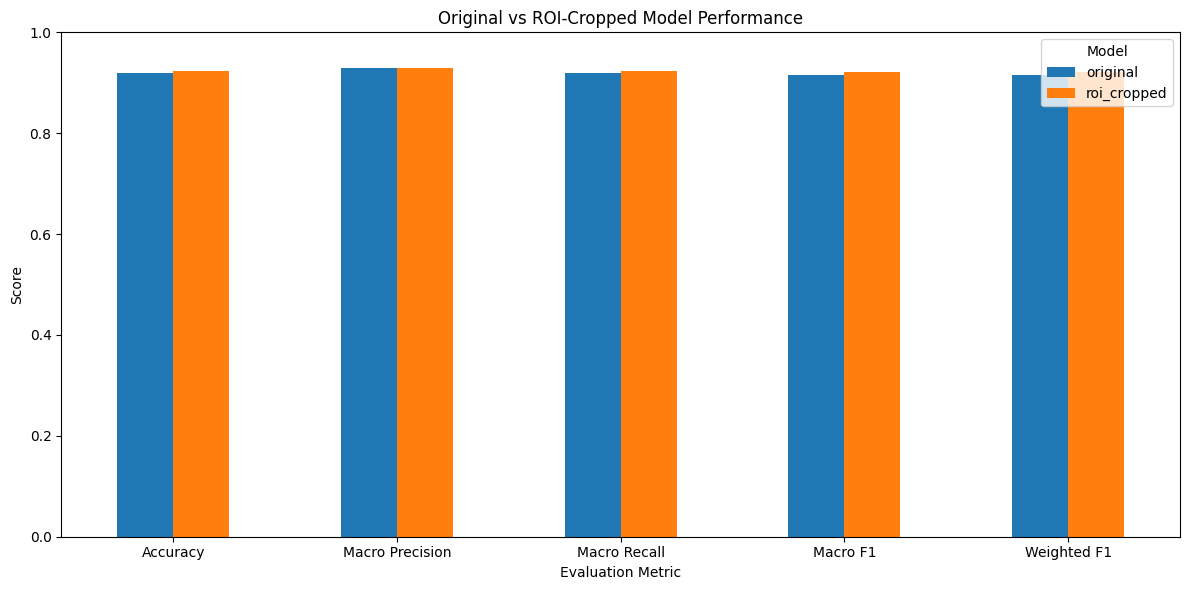

In [16]:
comparison = comparison.set_index("Condition")

comparison.to_csv(
    RESULT_DIR / "overall_comparison.csv"
)

metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

ax = comparison[metrics_to_plot].T.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "Original vs ROI-Cropped Model Performance"
)

ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "overall_comparison.png",
    dpi=160
)

plt.show()



In [17]:
difference = (
    comparison.loc["roi_cropped"] -
    comparison.loc["original"]
)

print("ROI - Original:")
display(difference.to_frame("Difference"))



ROI - Original:


,Difference
Accuracy,0.003125
Macro Precision,-0.000269
Macro Recall,0.003125
Macro F1,0.004114
Weighted F1,0.004114
Mean Confidence,0.004205


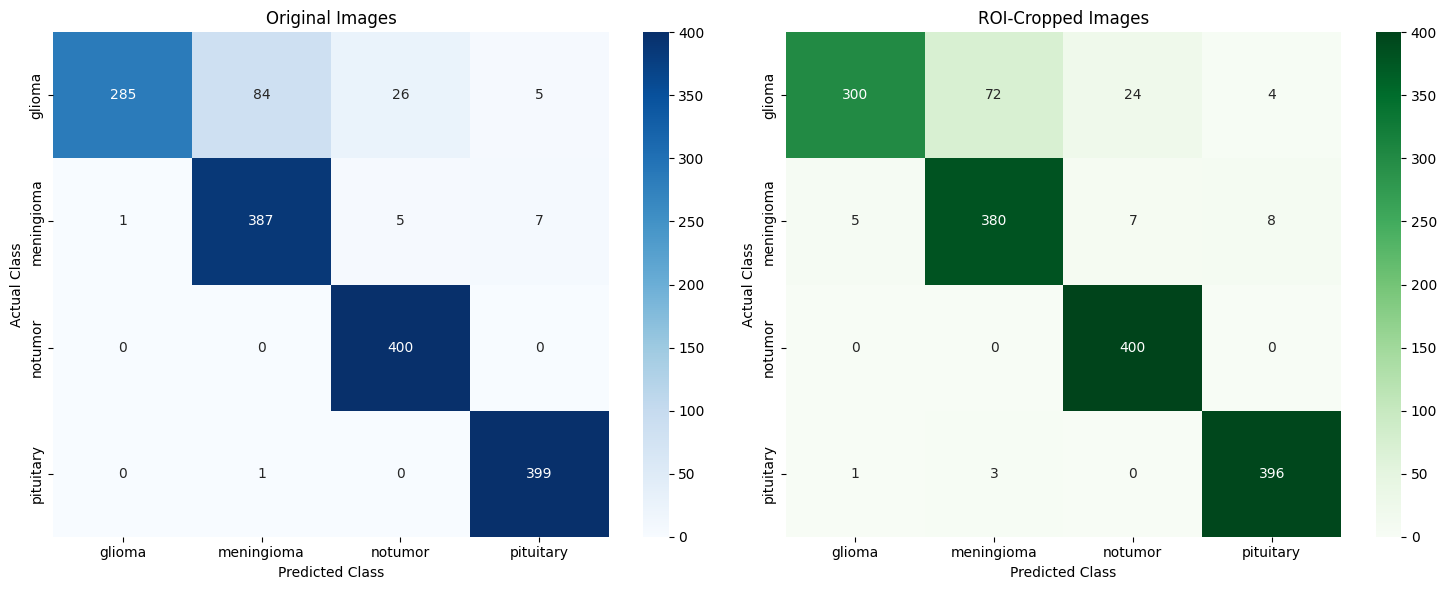

In [18]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

sns.heatmap(
    original_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("Original Images")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")


sns.heatmap(
    roi_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("ROI-Cropped Images")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "confusion_matrix_comparison.png",
    dpi=160
)

plt.show()



In [19]:
def get_class_metrics(report, model_name):

    rows = []

    for cls in CLASS_NAMES:

        rows.append({
            "Model": model_name,
            "Class": cls,
            "Precision": report[cls]["precision"],
            "Recall": report[cls]["recall"],
            "F1 Score": report[cls]["f1-score"]
        })

    return pd.DataFrame(rows)


original_class_metrics = get_class_metrics(
    original_report,
    "Original"
)

roi_class_metrics = get_class_metrics(
    roi_report,
    "ROI-Cropped"
)


class_comparison = pd.concat(
    [
        original_class_metrics,
        roi_class_metrics
    ],
    ignore_index=True
)

display(class_comparison)

class_comparison.to_csv(
    RESULT_DIR / "classwise_comparison.csv",
    index=False
)



,Model,Class,Precision,Recall,F1 Score
0,Original,glioma,0.996503,0.7125,0.830904
1,Original,meningioma,0.819915,0.9675,0.887615
2,Original,notumor,0.928074,1.0000,0.962696
3,Original,pituitary,0.970803,0.9975,0.983970
4,ROI-Cropped,glioma,0.980392,0.7500,0.849858
5,ROI-Cropped,meningioma,0.835165,0.9500,0.888889
6,ROI-Cropped,notumor,0.928074,1.0000,0.962696
7,ROI-Cropped,pituitary,0.970588,0.9900,0.980198


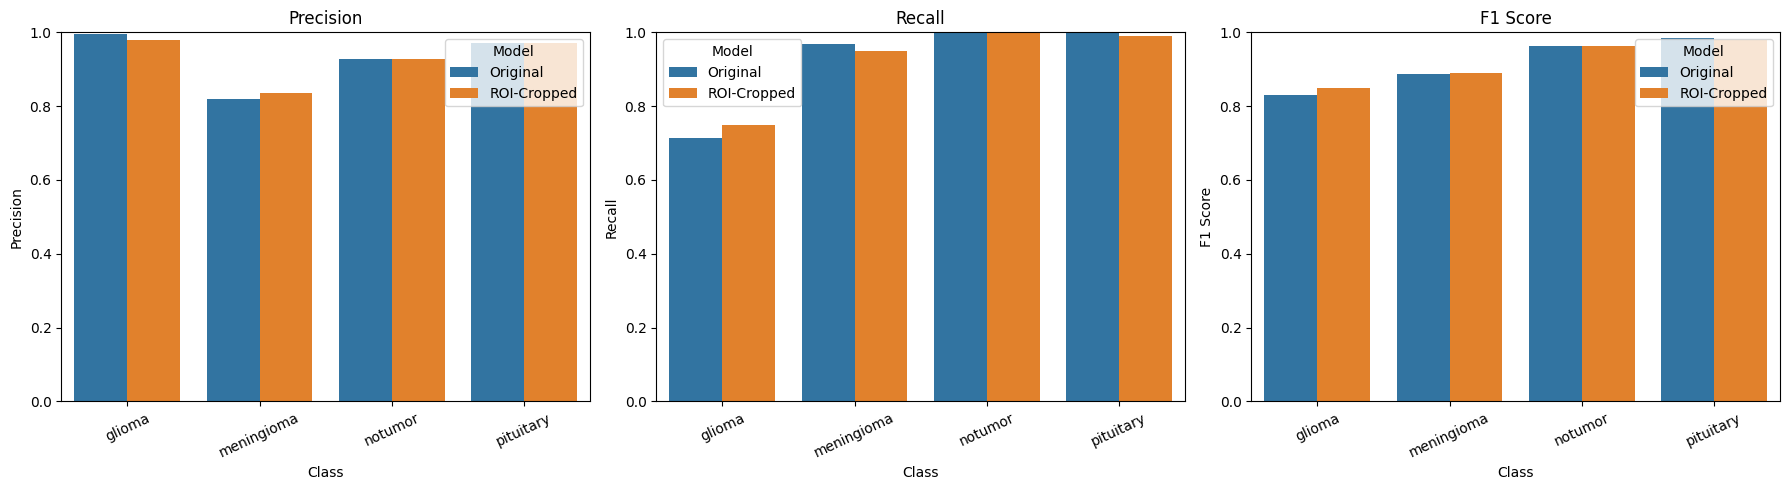

In [20]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, metric in zip(
    axes,
    ["Precision", "Recall", "F1 Score"]
):

    sns.barplot(
        data=class_comparison,
        x="Class",
        y=metric,
        hue="Model",
        ax=ax
    )

    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "classwise_metrics.png",
    dpi=160
)

plt.show()


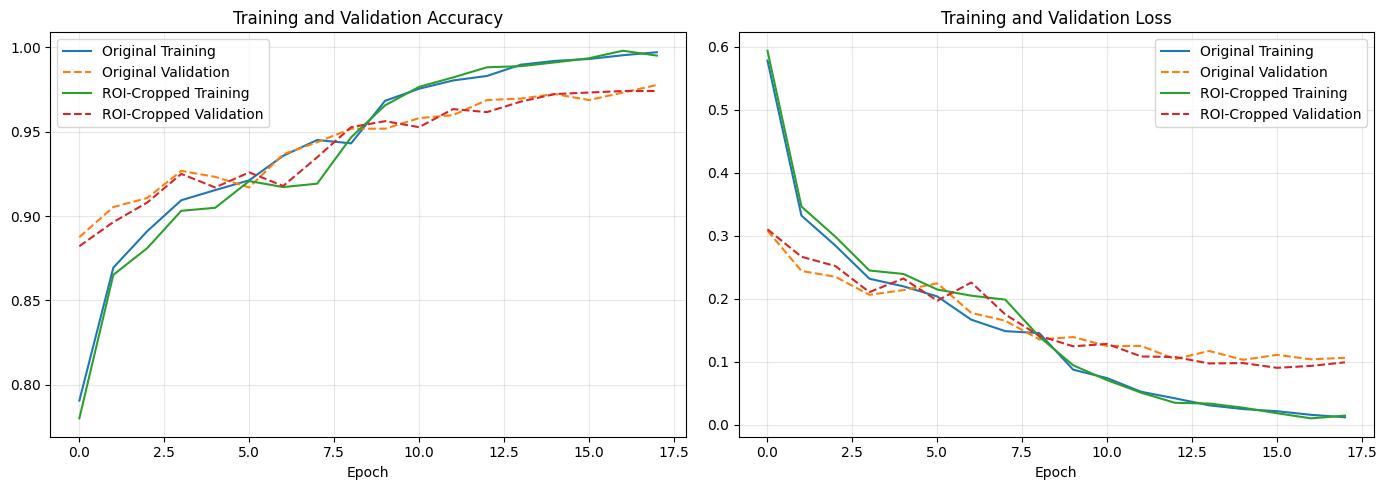

In [21]:
def plot_learning_curves():

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5)
    )

    histories = [
        (original_history, "Original"),
        (roi_history, "ROI-Cropped")
    ]

    for history, name in histories:

        axes[0].plot(
            history["accuracy"],
            label=f"{name} Training"
        )

        axes[0].plot(
            history["val_accuracy"],
            linestyle="--",
            label=f"{name} Validation"
        )

        axes[1].plot(
            history["loss"],
            label=f"{name} Training"
        )

        axes[1].plot(
            history["val_loss"],
            linestyle="--",
            label=f"{name} Validation"
        )

    axes[0].set_title("Training and Validation Accuracy")
    axes[1].set_title("Training and Validation Loss")

    for ax in axes:

        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        RESULT_DIR / "learning_curves_comparison.png",
        dpi=160
    )

    plt.show()


plot_learning_curves()



In [22]:
original_part = original_predictions[
    [
        "True Class",
        "Predicted Class",
        "Confidence",
        "Correct"
    ]
].copy()

original_part.columns = [
    "True Class",
    "Original Prediction",
    "Original Confidence",
    "Original Correct"
]


roi_part = roi_predictions[
    [
        "Predicted Class",
        "Confidence",
        "Correct"
    ]
].copy()

roi_part.columns = [
    "ROI Prediction",
    "ROI Confidence",
    "ROI Correct"
]


paired_predictions = pd.concat(
    [
        original_part.reset_index(drop=True),
        roi_part.reset_index(drop=True)
    ],
    axis=1
)


paired_predictions["Outcome"] = np.select(
    [
        paired_predictions["Original Correct"] &
        paired_predictions["ROI Correct"],

        paired_predictions["Original Correct"] &
        ~paired_predictions["ROI Correct"],

        ~paired_predictions["Original Correct"] &
        paired_predictions["ROI Correct"]
    ],
    [
        "Both Correct",
        "Original Only Correct",
        "ROI Only Correct"
    ],
    default="Both Wrong"
)


display(
    paired_predictions["Outcome"].value_counts()
)

paired_predictions.to_csv(
    RESULT_DIR / "paired_predictions.csv",
    index=False
)



Outcome
Both Correct             1455
Both Wrong                108
ROI Only Correct           21
Original Only Correct      16
Name: count, dtype: int64

In [23]:
summary = {

    "Experiment": "Original vs ROI-Cropped",

    "Architecture": "ResNet50",

    "Pretrained Weights": "ImageNet",

    "Image Size": IMG_SIZE,

    "Batch Size": BATCH_SIZE,

    "Random Seed": SEED,

    "Classes": CLASS_NAMES,

    "Original Model": original_metrics,

    "ROI Model": roi_metrics,

    "ROI Improvement": {
        metric: float(difference[metric])
        for metric in metrics_to_plot
    },

    "Prediction Outcomes": {
        str(k): int(v)
        for k, v in paired_predictions["Outcome"].value_counts().items()
    },

    "Limitations": [
        "Single random seed",
        "Image-level rather than patient-level splitting",
        "No patient identifiers available",
        "ROI extraction is not medically validated brain segmentation",
        "A single test-set comparison does not establish clinical superiority"
    ]
}


with open(
    RESULT_DIR / "experiment_summary.json",
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )


print(json.dumps(summary, indent=4))

print("\nExperiment completed.")
print("Results saved at:", RESULT_DIR)

TypeError: Object of type float32 is not JSON serializable